# LSTM

Pronóstico de la semana siguiente, hora por hora (h = 3 a 9), con una LSTM armada como en
Salazar-Peña et al. (2025): tres capas LSTM con dropout, Adam, pérdida MAE y búsqueda
bayesiana de hiperparámetros.

Se entrena hasta 2021 y se valida en 2022. El test es el mismo de XGBoost y SARIMAX
(2023-2025 y 2026) para poder comparar los tres.

In [24]:
%pip install -q keras-tuner

In [25]:
import gdown
import pandas as pd

# ID del archivo de Google Drive compartido (Nuevo panel preprocesado)
file_id = '1XI8s9r9LyLLkbSxgcTyvfTmTgWEx0iNx'
url = f'https://drive.google.com/uc?id={file_id}'
output = 'panel_lstm_modelo.csv.gz'

# Descargar el archivo
gdown.download(url, output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1XI8s9r9LyLLkbSxgcTyvfTmTgWEx0iNx
To: /content/panel_lstm_modelo.csv.gz
100%|██████████| 33.6M/33.6M [00:00<00:00, 187MB/s]


'panel_lstm_modelo.csv.gz'

In [26]:
# Cargar el archivo directamente como un CSV plano (sin compresión gzip)
df_preview = pd.read_csv(output, nrows=10)

display(df_preview.head())
print("Columnas disponibles:", df_preview.columns.tolist())

,fecha,hora,bloque,precio,lp,hora_sin,hora_cos,dia_semana,dia_semana_sin,dia_semana_cos,...,presion_hidro_horaria,aportes_media_hist,aportes_pct_sistema,aportes_caudal_pct,redespacho_vs_programa,aportes_pct_rio,error_cmg_despacho,aportes_top3_pct,hhi_aportes_rios,cmg_redespacho
0,2015-01-01,1,seleccion,184.21,5.21608,0.000000,1.000000,3,0.433884,-0.900969,...,2.24544,94.23,0.6885,0.637642,-0.053783,0.702224,-0.005684,0.324613,693.315,5.19296
1,2015-01-01,2,seleccion,178.21,5.18296,0.258819,0.965926,3,0.433884,-0.900969,...,2.15577,94.23,0.6885,0.637642,-0.075069,0.702224,-0.038798,0.324613,693.315,4.90513
2,2015-01-01,3,seleccion,178.21,5.18296,0.500000,0.866025,3,0.433884,-0.900969,...,2.06214,94.23,0.6885,0.637642,-0.086959,0.702224,0.012479,0.324613,693.315,4.69593
3,2015-01-01,4,seleccion,178.21,5.18296,0.707107,0.707107,3,0.433884,-0.900969,...,1.99612,94.23,0.6885,0.637642,-0.088452,0.702224,0.012479,0.324613,693.315,4.69593
4,2015-01-01,5,seleccion,178.21,5.18296,0.866025,0.500000,3,0.433884,-0.900969,...,1.94543,94.23,0.6885,0.637642,-0.062768,0.702224,0.012479,0.324613,693.315,4.90513


Columnas disponibles: ['fecha', 'hora', 'bloque', 'precio', 'lp', 'hora_sin', 'hora_cos', 'dia_semana', 'dia_semana_sin', 'dia_semana_cos', 'es_festivo', 'mes', 'mes_sin', 'mes_cos', 'dia_ano_sin', 'dia_ano_cos', 'dia_semana_k1', 'es_festivo_k1', 'dia_semana_k2', 'es_festivo_k2', 'dia_semana_k3', 'es_festivo_k3', 'dia_semana_k4', 'es_festivo_k4', 'dia_semana_k5', 'es_festivo_k5', 'dia_semana_k6', 'es_festivo_k6', 'dia_semana_k7', 'es_festivo_k7', 'y_h3', 'y_h4', 'y_h5', 'y_h6', 'y_h7', 'y_h8', 'y_h9', 'cmg_hoy_vs_precio', 'cmg_despacho', 'disp_decl_hoy_rel', 'brecha_escasez', 'presion_hidro_horaria', 'aportes_media_hist', 'aportes_pct_sistema', 'aportes_caudal_pct', 'redespacho_vs_programa', 'aportes_pct_rio', 'error_cmg_despacho', 'aportes_top3_pct', 'hhi_aportes_rios', 'cmg_redespacho']


In [27]:
import json
from pathlib import Path

import keras
import keras_tuner as kt
import numpy as np
import pandas as pd
from keras import layers
from scipy import stats

keras.utils.set_random_seed(0)

RUTA = Path("paneles/panel_lstm_modelo.csv.gz")
if not RUTA.exists():
    RUTA = Path("panel_lstm_modelo.csv.gz")
SALIDA = Path("resultados/modelo_lstm")
SALIDA.mkdir(parents=True, exist_ok=True)

HS = list(range(3, 10))
DIAS_ENTRADA = 7
VARIABLES = ["cmg_hoy_vs_precio", "cmg_despacho", "disp_decl_hoy_rel", "brecha_escasez",
             "presion_hidro_horaria"]
CALENDARIO = ["hora_sin", "hora_cos", "dia_semana_sin", "dia_semana_cos", "es_festivo",
              "dia_ano_sin", "dia_ano_cos"] + [f"es_festivo_k{k}" for k in range(1, 8)]
COLUMNAS = ["lp"] + VARIABLES + CALENDARIO

INICIO = "2015-03-01"
FIN_ENTRENAMIENTO = "2021-12-31"
FIN_VALIDACION = "2022-12-31"
FIN_TEST = "2025-12-31"
FIN_2026 = "2026-10-06"
BLOQUES = {"h = 3 a 9": HS, "h = 3": [3], "h = 3 a 7": [3, 4, 5, 6, 7], "h = 8 a 9": [8, 9]}

CORRER_TEST = False
REENTRENAR = "mensual"

## Datos

Cada fila del panel tiene lo que se sabe el día en que se pronostica (paso 2e). La entrada
son los últimos 7 días, hora por hora (168 pasos), y la salida las 168 horas de h = 3 a 9.

In [28]:
# Cargar el panel directamente como un CSV plano
panel = pd.read_csv(output, parse_dates=["fecha"]).sort_values(["fecha", "hora"]).reset_index(drop=True)
assert (panel.groupby("fecha").size() == 24).all()

f = pd.DatetimeIndex(panel["fecha"].drop_duplicates())
n_dias = len(f)
X_dia = panel[COLUMNAS].to_numpy(np.float32).reshape(n_dias, 24, len(COLUMNAS))
Y_dia = (panel[[f"y_h{h}" for h in HS]].to_numpy(np.float32)
         .reshape(n_dias, 24, len(HS)).transpose(0, 2, 1))

LP = panel["lp"].to_numpy(np.float32).reshape(n_dias, 24)
Y_sem = np.full_like(Y_dia, np.nan)
for j, h in enumerate(HS):
    k = 7 * int(np.ceil(h / 7)) - h
    Y_sem[k:, j] = LP[:n_dias - k] - LP[k:]

ok = np.zeros(n_dias, bool)
for i in range(DIAS_ENTRADA - 1, n_dias):
    ok[i] = not np.isnan(X_dia[i - DIAS_ENTRADA + 1:i + 1]).any()

def origenes(desde, hasta, completos=True):
    m = ok & (f >= pd.Timestamp(desde))
    if completos:
        m &= (f + pd.Timedelta(days=max(HS)) <= pd.Timestamp(hasta)) & ~np.isnan(Y_dia).any(axis=(1, 2))
    else:
        m &= f <= pd.Timestamp(hasta)
    return np.flatnonzero(m)

def ventanas(idx):
    X = np.stack([X_dia[i - DIAS_ENTRADA + 1:i + 1].reshape(-1, len(COLUMNAS)) for i in idx])
    return X, Y_dia[idx].reshape(len(idx), -1)

idx_tr = origenes(INICIO, FIN_ENTRENAMIENTO)
idx_va = origenes("2022-01-01", FIN_VALIDACION)
X_tr, Y_tr = ventanas(idx_tr)
X_va, Y_va = ventanas(idx_va)
print(f"entrenamiento: {len(idx_tr)} días, {f[idx_tr[0]].date()} a {f[idx_tr[-1]].date()}")
print(f"validación: {len(idx_va)} días, {f[idx_va[0]].date()} a {f[idx_va[-1]].date()}")
print("entrada", X_tr.shape, "salida", Y_tr.shape)

entrenamiento: 2489 días, 2015-03-01 a 2021-12-22
validación: 356 días, 2022-01-01 a 2022-12-22
entrada (2489, 168, 20) salida (2489, 168)


## Modelo

Igual que en el paper: tres capas LSTM con tanh, dropout después de cada una y una capa
densa con las 168 salidas. Las unidades van de 60 a 360 de a 30, el dropout de 0,2 a 0,5 y la
tasa de aprendizaje de Adam de 1e-6 a 1e-2 en escala logarítmica.

In [29]:
def escala(X, Y):
    mx, sx = X.reshape(-1, X.shape[-1]).mean(0), X.reshape(-1, X.shape[-1]).std(0) + 1e-6
    my, sy = Y.mean(0), Y.std(0) + 1e-6
    return (lambda X_: (X_ - mx) / sx), (lambda Y_: (Y_ - my) / sy), (lambda Z: Z * sy + my)


def construir(hp):
    modelo = keras.Sequential([keras.Input(shape=(DIAS_ENTRADA * 24, len(COLUMNAS)))])
    for capa in range(1, 4):
        modelo.add(layers.LSTM(hp.Int(f"unidades_{capa}", 60, 360, step=30), activation="tanh",
                               return_sequences=capa < 3))
        modelo.add(layers.Dropout(hp.Float(f"dropout_{capa}", 0.2, 0.5, step=0.1)))
    modelo.add(layers.Dense(len(HS) * 24))
    tasa = hp.Float("tasa", 1e-6, 1e-2, sampling="log")
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss="mae")
    return modelo


def entrenar(hp, idx, epocas, idx_val=None):
    X, Y = ventanas(idx)
    nx, ny, volver = escala(X, Y)
    modelo = construir(hp)
    val, parar = None, []
    if idx_val is not None:
        Xv, Yv = ventanas(idx_val)
        val = (nx(Xv), ny(Yv))
        parar = [keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)]
    hist = modelo.fit(nx(X), ny(Y), validation_data=val, epochs=epocas, batch_size=32,
                      callbacks=parar, verbose=0)
    return modelo, nx, volver, hist


def pronosticar(modelo, nx, volver, idx):
    X, _ = ventanas(idx)
    return volver(modelo.predict(nx(X), verbose=0)).reshape(len(idx), len(HS), 24)

## Búsqueda de hiperparámetros

Optimización bayesiana con 10 combinaciones de 10 épocas cada una, como en el paper.
Entrena hasta 2021 y mide la pérdida en 2022.

In [30]:
nx, ny, _ = escala(X_tr, Y_tr)
buscador = kt.BayesianOptimization(construir, objective="val_loss", max_trials=10, seed=0,
                                   directory="busqueda_lstm", project_name="lstm")
buscador.search(nx(X_tr), ny(Y_tr), validation_data=(nx(X_va), ny(Y_va)), epochs=10, batch_size=32)

mejor = buscador.get_best_hyperparameters(1)[0]
pd.Series(mejor.values)

Trial 10 Complete [00h 00m 23s]
val_loss: 0.6518045663833618

Best val_loss So Far: 0.6348263025283813
Total elapsed time: 00h 03m 57s


,0
unidades_1,330.000000
dropout_1,0.200000
unidades_2,210.000000
dropout_2,0.300000
unidades_3,150.000000
dropout_3,0.300000
tasa,0.003697


## Validación (2022)

El mejor modelo se entrena hasta 100 épocas, con parada temprana en 2022. Se mide con el
criterio de la tesis: RMSE del logaritmo frente al mejor de los dos ingenuos y
Diebold-Mariano.

In [31]:
def media_y_ee(d, L):
    n = len(d)
    u = d - d.mean()
    v = np.mean(u * u)
    for l in range(1, min(L, n - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * np.mean(u[l:] * u[:-l])
    return d.mean(), np.sqrt(v / n)


def criterio(idx, pred, tope):
    y = Y_dia[idx].copy()
    fuera = (f[idx].to_numpy()[:, None] + np.array(HS, dtype="timedelta64[D]")) > np.datetime64(tope)
    y[fuera] = np.nan
    filas = []
    for nombre, hs in BLOQUES.items():
        j = [HS.index(h) for h in hs]
        e = y[:, j] - pred[:, j]
        ingenuos = {"del día": y[:, j], "semanal": y[:, j] - Y_sem[idx][:, j]}
        rmse = {k: np.sqrt(np.nanmean(v ** 2)) for k, v in ingenuos.items()}
        ref = min(rmse, key=rmse.get)
        d = np.nanmean((e ** 2 - ingenuos[ref] ** 2).reshape(len(idx), -1), axis=1)
        m, ee = media_y_ee(d[~np.isnan(d)], max(hs) - 1 + 7)
        r = np.sqrt(np.nanmean(e ** 2))
        mejora, p = 100 * (1 - r / rmse[ref]), 2 * stats.norm.sf(abs(m / ee))
        filas.append(dict(bloque=nombre, rmse_log=r, mejor_ingenuo=ref, rmse_ingenuo=rmse[ref],
                          mejora=mejora, dm_t=m / ee, dm_p=p, funciona=mejora >= 5 and p < 0.05))
    return pd.DataFrame(filas).set_index("bloque").round(4)


modelo, nx, volver, hist = entrenar(mejor, idx_tr, 100, idx_va)
epocas = int(np.argmin(hist.history["val_loss"]) + 1)
print("mejor época:", epocas)
criterio(idx_va, pronosticar(modelo, nx, volver, idx_va), FIN_VALIDACION)

mejor época: 6


,rmse_log,mejor_ingenuo,rmse_ingenuo,mejora,dm_t,dm_p,funciona
bloque,,,,,,,
h = 3 a 9,0.2793,del día,0.3286,14.9791,-3.9508,0.0001,True
h = 3,0.2096,del día,0.2727,23.1408,-4.6448,0.0000,True
h = 3 a 7,0.2575,del día,0.3082,16.4566,-4.3327,0.0000,True
h = 8 a 9,0.3277,del día,0.3747,12.5367,-3.3112,0.0009,True


In [36]:
CORRER_TEST = True

## Test

Se corre una sola vez, con `CORRER_TEST = True` y la configuración ya cerrada. Se reentrena
cada mes con todo lo anterior, como XGBoost y SARIMAX, con las épocas de la validación. Con
`REENTRENAR = "anual"` es unas 10 veces más rápido.

In [37]:
def walk_forward(desde, hasta):
    cortes = pd.date_range(desde, hasta, freq="MS" if REENTRENAR == "mensual" else "YS")
    tope = pd.Timestamp(hasta)
    partes = []
    for k, c in enumerate(cortes):
        sig = cortes[k + 1] if k + 1 < len(cortes) else tope + pd.Timedelta(days=1)
        tr = origenes(INICIO, c - pd.Timedelta(days=1))
        ev = origenes(c, min(sig - pd.Timedelta(days=1), tope - pd.Timedelta(days=min(HS))), completos=False)
        modelo, nx, volver, _ = entrenar(mejor, tr, epocas)
        partes.append((ev, pronosticar(modelo, nx, volver, ev)))
        print(c.date(), len(tr), "días de entrenamiento", flush=True)
    return np.concatenate([p[0] for p in partes]), np.concatenate([p[1] for p in partes])


def a_filas(idx, pred, tope):
    n = len(idx)
    d = pd.DataFrame({"fecha": np.repeat(f[idx], len(HS) * 24),
                      "hora": np.tile(np.arange(1, 25), n * len(HS)),
                      "h": np.tile(np.repeat(HS, 24), n),
                      "y_hat": pred.reshape(-1)})
    return d[d["fecha"] + pd.to_timedelta(d["h"], unit="D") <= pd.Timestamp(tope)]


if CORRER_TEST:
    resultados = []
    for nombre, desde, hasta in [("2023_2025", "2023-01-01", FIN_TEST), ("2026", "2026-01-01", FIN_2026)]:
        idx, pred = walk_forward(desde, hasta)
        a_filas(idx, pred, hasta).to_csv(SALIDA / f"prueba_{nombre}.csv.gz", index=False)
        resultados.append(criterio(idx, pred, hasta).assign(periodo=nombre))
    json.dump({**mejor.values, "epocas": epocas, "dias_entrada": DIAS_ENTRADA, "perdida": "mae",
               "reentrenar": REENTRENAR}, open(SALIDA / "configuracion_final.json", "w"), indent=2)
    display(pd.concat(resultados))

2023-01-01 2854 días de entrenamiento
2023-02-01 2885 días de entrenamiento


2023-03-01 2913 días de entrenamiento


2023-04-01 2944 días de entrenamiento
2023-05-01 2974 días de entrenamiento
2023-06-01 3005 días de entrenamiento
2023-07-01 3035 días de entrenamiento
2023-08-01 3066 días de entrenamiento
2023-09-01 3097 días de entrenamiento
2023-10-01 3127 días de entrenamiento
2023-11-01 3158 días de entrenamiento
2023-12-01 3188 días de entrenamiento
2024-01-01 3219 días de entrenamiento
2024-02-01 3250 días de entrenamiento
2024-03-01 3279 días de entrenamiento
2024-04-01 3310 días de entrenamiento
2024-05-01 3340 días de entrenamiento
2024-06-01 3371 días de entrenamiento
2024-07-01 3401 días de entrenamiento
2024-08-01 3432 días de entrenamiento
2024-09-01 3463 días de entrenamiento
2024-10-01 3493 días de entrenamiento
2024-11-01 3524 días de entrenamiento
2024-12-01 3554 días de entrenamiento
2025-01-01 3585 días de entrenamiento
2025-02-01 3616 días de entrenamiento
2025-03-01 3644 días de entrenamiento
2025-04-01 3675 días de entrenamiento
2025-05-01 3705 días de entrenamiento
2025-06-01 3

/tmp/ipykernel_855/500202394.py:21: RuntimeWarning: Mean of empty slice
  d = np.nanmean((e ** 2 - ingenuos[ref] ** 2).reshape(len(idx), -1), axis=1)


2026-01-01 3950 días de entrenamiento
2026-02-01 3981 días de entrenamiento
2026-03-01 4009 días de entrenamiento
2026-04-01 4040 días de entrenamiento
2026-05-01 4070 días de entrenamiento
2026-06-01 4101 días de entrenamiento
2026-07-01 4131 días de entrenamiento
2026-08-01 4162 días de entrenamiento
2026-09-01 4193 días de entrenamiento
2026-10-01 4223 días de entrenamiento


/tmp/ipykernel_855/500202394.py:21: RuntimeWarning: Mean of empty slice
  d = np.nanmean((e ** 2 - ingenuos[ref] ** 2).reshape(len(idx), -1), axis=1)


,rmse_log,mejor_ingenuo,rmse_ingenuo,mejora,dm_t,dm_p,funciona,periodo
bloque,,,,,,,,
h = 3 a 9,0.4418,del día,0.5018,11.9609,-5.7399,0.0000,True,2023_2025
h = 3,0.3457,del día,0.4115,15.9753,-7.7035,0.0000,True,2023_2025
h = 3 a 7,0.4096,del día,0.4720,13.2262,-6.2680,0.0000,True,2023_2025
h = 8 a 9,0.5138,del día,0.5698,9.8250,-4.6017,0.0000,True,2023_2025
h = 3 a 9,0.3791,del día,0.4353,12.9060,-3.2064,0.0013,True,2026
h = 3,0.2901,del día,0.3524,17.6766,-3.8527,0.0001,True,2026
h = 3 a 7,0.3499,del día,0.4087,14.3772,-3.5002,0.0005,True,2026
h = 8 a 9,0.4446,del día,0.4964,10.4373,-2.6671,0.0076,True,2026


## Semana final

Pronóstico del 9 al 15 de octubre de 2026 con el corte del 6 de octubre, contra el precio real
que ya se bajó para XGBoost.

In [33]:
if CORRER_TEST:
    corte = pd.Timestamp(FIN_2026)
    modelo, nx, volver, _ = entrenar(mejor, origenes(INICIO, corte), epocas)
    i = np.flatnonzero(f == corte)
    final = a_filas(i, pronosticar(modelo, nx, volver, i), corte + pd.Timedelta(days=max(HS)))
    final["fecha_objetivo"] = final["fecha"] + pd.to_timedelta(final["h"], unit="D")
    final["precio_pron"] = panel.loc[(panel["fecha"] == corte), "precio"].to_numpy()[final["hora"] - 1] * np.exp(final["y_hat"])
    real = pd.read_csv("resultados/modelo_xgboost/precio_real_final.csv", parse_dates=["fecha_objetivo"])
    final = final.merge(real, on=["fecha_objetivo", "hora"])
    final.to_csv(SALIDA / "pronostico_final.csv", index=False)
    e = np.log(final["precio_real"]) - np.log(final["precio_pron"])
    print(f"RMSE log {np.sqrt(np.mean(e ** 2)):.3f}, MAPE "
          f"{100 * np.mean(np.abs(final['precio_real'] - final['precio_pron']) / final['precio_real']):.1f}%")

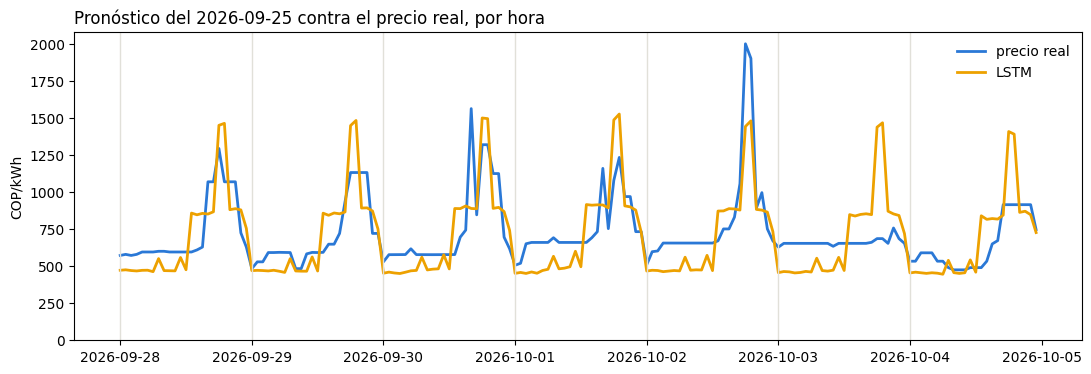

In [38]:
import matplotlib.pyplot as plt

precio = panel.set_index(["fecha", "hora"])["precio"]
prueba = pd.concat([pd.read_csv(SALIDA / f"prueba_{p}.csv.gz", parse_dates=["fecha"])
                    for p in ("2023_2025", "2026")])


def grafica(corte):
    corte = pd.Timestamp(corte)
    s = prueba[prueba["fecha"] == corte].sort_values(["h", "hora"]).copy()
    s["fecha_objetivo"] = s["fecha"] + pd.to_timedelta(s["h"], unit="D")
    s["momento"] = s["fecha_objetivo"] + pd.to_timedelta(s["hora"] - 1, unit="h")
    s["LSTM"] = precio.loc[corte].reindex(s["hora"]).to_numpy() * np.exp(s["y_hat"])
    s["precio real"] = precio.reindex(pd.MultiIndex.from_arrays([s["fecha_objetivo"], s["hora"]])).to_numpy()
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(s["momento"], s["precio real"], color="#2a78d6", lw=2, label="precio real")
    ax.plot(s["momento"], s["LSTM"], color="#eda100", lw=2, label="LSTM")
    for d in s["fecha_objetivo"].unique():
        ax.axvline(d, color="#e1e0d9", lw=1)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("COP/kWh")
    ax.set_title(f"Pronóstico del {corte.date()} contra el precio real, por hora", loc="left")
    ax.legend(frameon=False)
    plt.show()


grafica("2026-09-25")

In [39]:
final = pd.read_csv(SALIDA / "pronostico_final.csv", parse_dates=["fecha_objetivo"])
final["momento"] = final["fecha_objetivo"] + pd.to_timedelta(final["hora"] - 1, unit="h")
final = final.sort_values("momento")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(final["momento"], final["precio_real"], color="#2a78d6", lw=2, label="precio real")
ax.plot(final["momento"], final["precio_pron"], color="#eda100", lw=2, label="LSTM")
for d in final["fecha_objetivo"].unique():
    ax.axvline(d, color="#e1e0d9", lw=1)
ax.set_ylim(bottom=0)
ax.set_ylabel("COP/kWh")
ax.set_title("Semana final: pronóstico del 6 de octubre contra el precio real, por hora", loc="left")
ax.legend(frameon=False)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'resultados/modelo_lstm/pronostico_final.csv'